# 21-课程总结


## 1. 这只是开始：具身智能的三条线

本篇对应《具身智能机器人实战》第 21 节《课程总结》。课件首页题为“这只是开始”，副标题为“具身智能的三条线”。本节先回顾课程的技术主线，再介绍后续发展方向，最后提出分析机器人系统时可以继续追问的问题。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/21_课程总结.pptx` 全部 14 页。第 3～5 页回顾技术过程，第 6 页介绍工程师发展方向，第 7～9 页展示参数对齐、步态优化与物体交互，第 10、11 页提出技术问题与创造者视角。第 2、12～14 页主要为结课鼓励、告别及品牌信息，文字简要归纳，装饰图片与招生信息省略。

课件以总结和示意图为主，没有新增可直接执行的程序、训练配置或实机操作步骤。下面保留教学图，必要的概念澄清标为“工程补充”。未转录配套视频 `21_课程总结.mp4`，也未读取网盘中的 `code.zip`。


## 2. 课程主线：模型、状态、控制、策略与交互

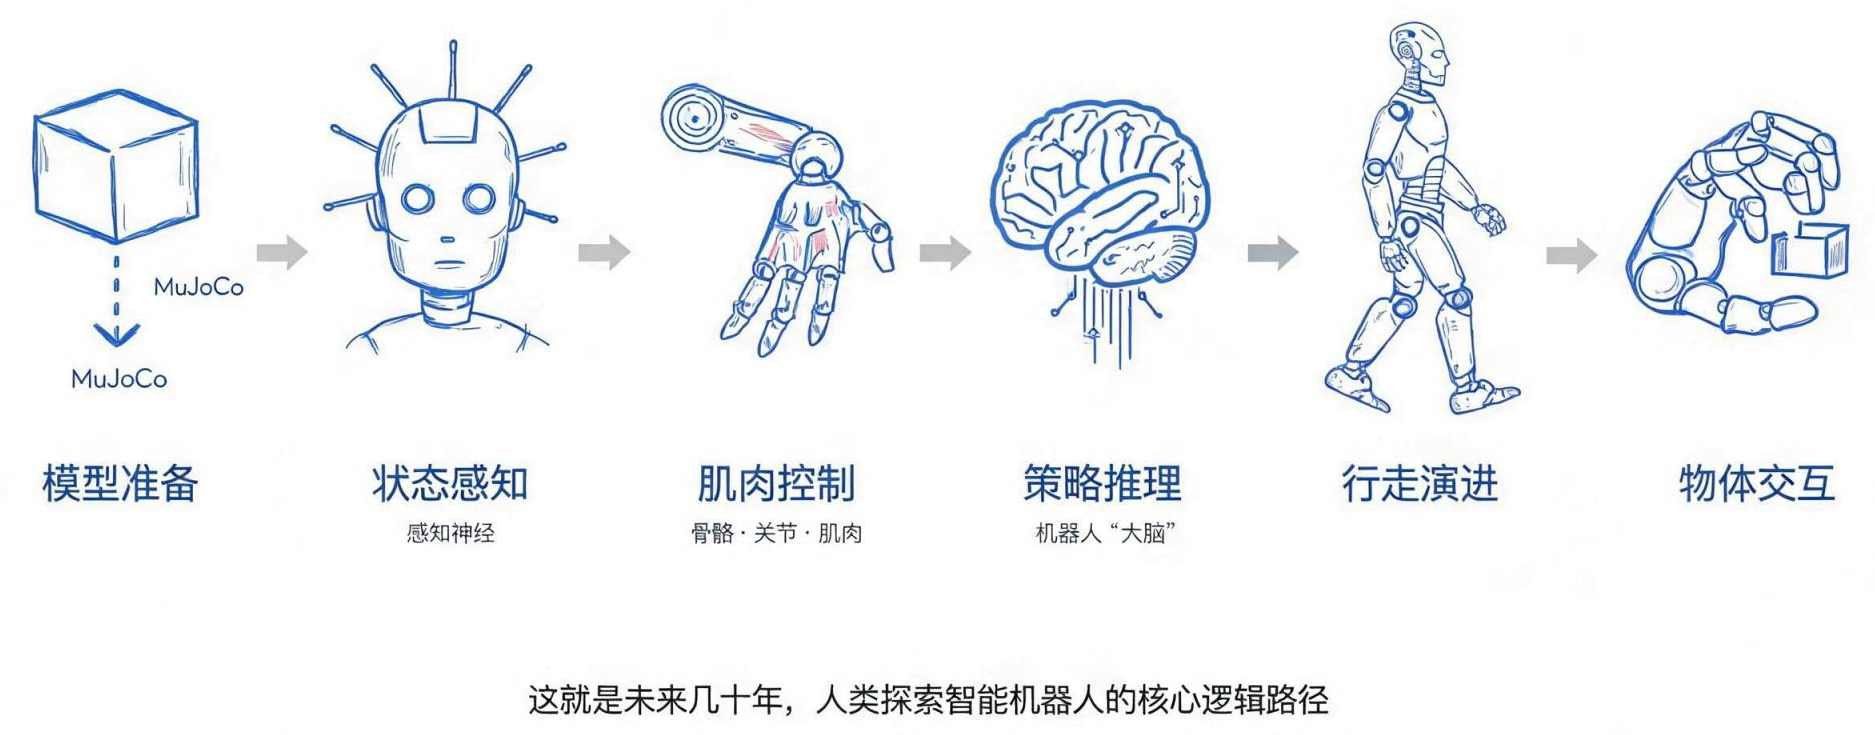

*原课件第 3 页：按六个环节回顾机器人仿真开发过程。*

| 课件中的环节 | 本系列中需要掌握的内容 |
|---|---|
| 模型准备 | 把机器人及场景加载到 MuJoCo，理解模型中的关节、连杆与执行器 |
| 状态感知 | 读取位置、速度和姿态等状态，理解坐标系与观测的含义 |
| 肌肉控制 | 把目标转换为关节控制输入，理解 PD 控制与输出限制 |
| 策略推理 | 根据观测生成动作，再把动作转换为目标关节角 |
| 行走演进 | 结合状态反馈、运动指令和调试逐步观察行走表现 |
| 物体交互 | 在场景中加入对象，进一步理解目标感知、空间关系与交互任务 |

课件用“感知神经”“骨骼、关节、肌肉”和机器人“大脑”作类比，帮助把程序中的不同职责联系起来。模型提供身体与环境，状态描述当前情况，策略决定动作，控制环节把动作落实为驱动，环境和身体变化又产生新的状态。

图中的箭头用于回顾学习路线。**工程补充：**实际运行时，策略、控制、仿真与状态读取会反复执行，不能把这张图理解为每个环节只运行一次，也不能仅凭流程图认定各项任务已经在同一个程序中验证完成。


## 3. 具身任务的结果发生在物理世界

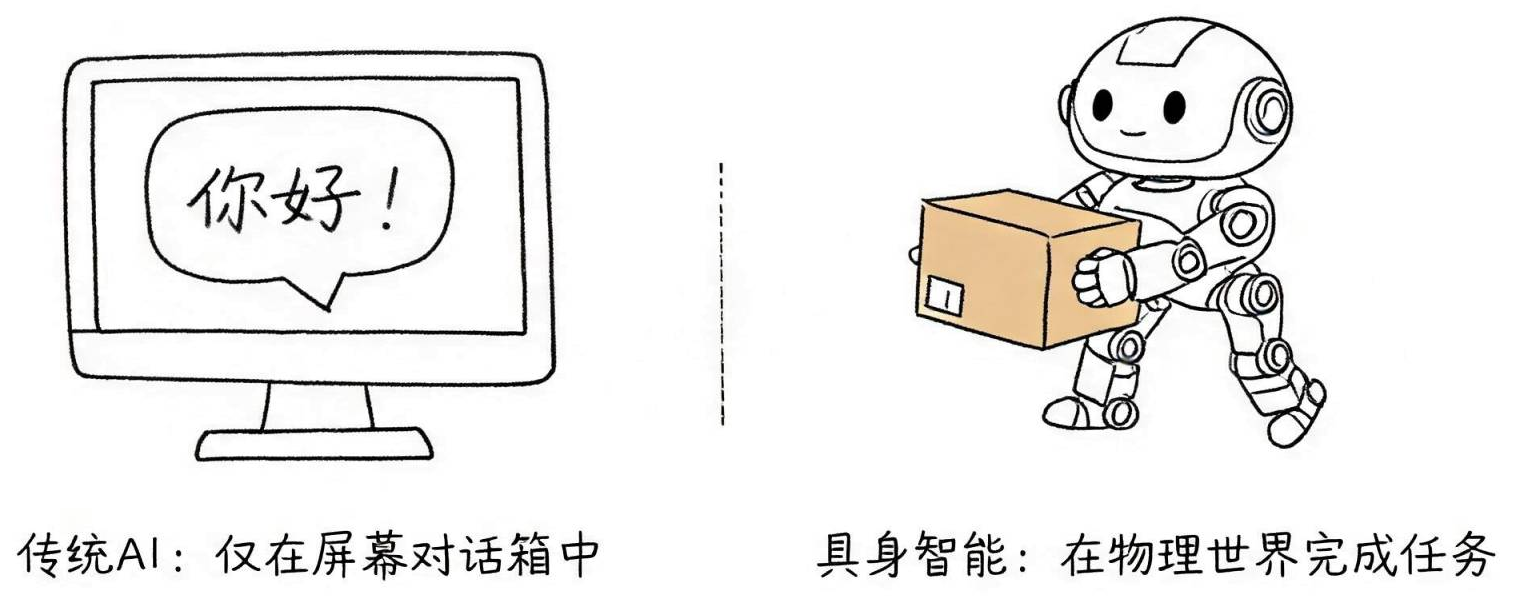

*原课件第 4 页：左侧为屏幕中的“你好”，右侧为机器人搬箱子。*

课件用“传统 AI：仅在屏幕对话框中”与“具身智能：在物理世界完成任务”作对比，强调本课程关注的结果：机器人需要通过身体运动与环境交互，完成行走、搬运等任务。

对于这类任务，判断结果要落实到动作产生了什么效果。例如，搬运需要关注物体是否随机器人移动，行走需要关注身体是否稳定、实际运动是否符合指令。仅产生一条描述动作的文本，还没有说明物理任务已经完成。

**工程补充：**这里是对任务形式的简化对比，传统 AI 的应用并不限于聊天。本课程主要在仿真环境中学习这些关系，仿真结果与真实机器人完成任务仍需分别验证。


## 4. 三个关键回顾：PD、限幅与观测

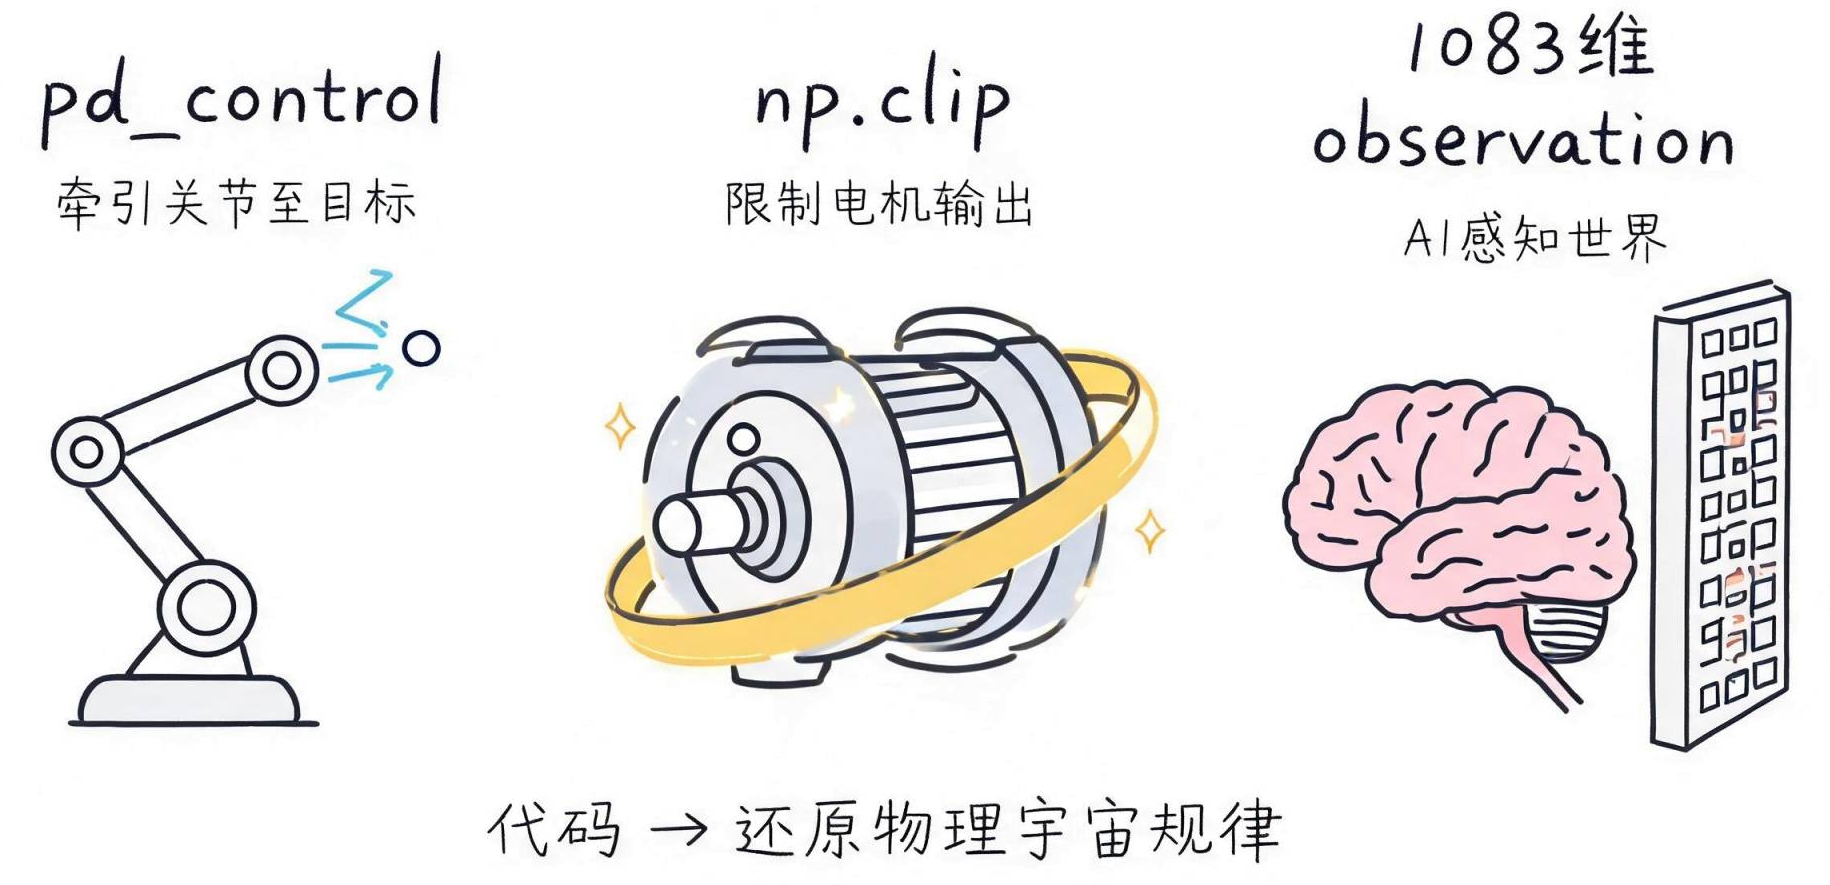

*原课件第 5 页：`pd_control`“牵引关节至目标”，`np.clip`“限制电机输出”，1083 维 `observation` 供策略获取信息。*

这三个概念分别回答控制过程中的不同问题：

| 概念 | 需要回答的问题 | 与前面课程的联系 |
|---|---|---|
| `pd_control` | 当前关节偏离目标时，应产生怎样的控制作用 | 第 08 节根据位置误差与速度误差生成力矩 |
| `np.clip` | 算出的输出超过允许范围时怎样处理 | 第 09 节讨论执行器能力边界与限幅 |
| `observation` | 策略根据哪些信息决定动作 | 第 12 节整理身体状态历史与用户命令 |

第 12 节的维度关系可以在这里一并回顾：

$$
d_{\mathrm{obs}}
=15\times(22+22+22+3+3)+3
=15\times72+3
=1083
$$

每帧包含关节位置偏差、关节速度、上一帧 Action、身体角速度和重力方向。15 帧身体信息共 1080 维，再加入一次 3 维用户命令。课件本页没有重新展开这些数据的构造代码。

**工程补充：**1083 是这套观测方案的长度，不能当作所有机器人策略的通用维度，也不能认为其中已经包含相机图像。`np.clip` 按给定上下界裁剪数值，实际限幅范围与输入的物理含义仍需核对执行器配置。控制输出符合范围，也不保证目标一定可达。

课件用“代码还原物理宇宙规律”概括这一页。可以把它理解为：程序中的误差、输出限制和状态数据，都需要对应到机器人实际要解决的运动问题。


## 5. 继续前行的三个发展方向

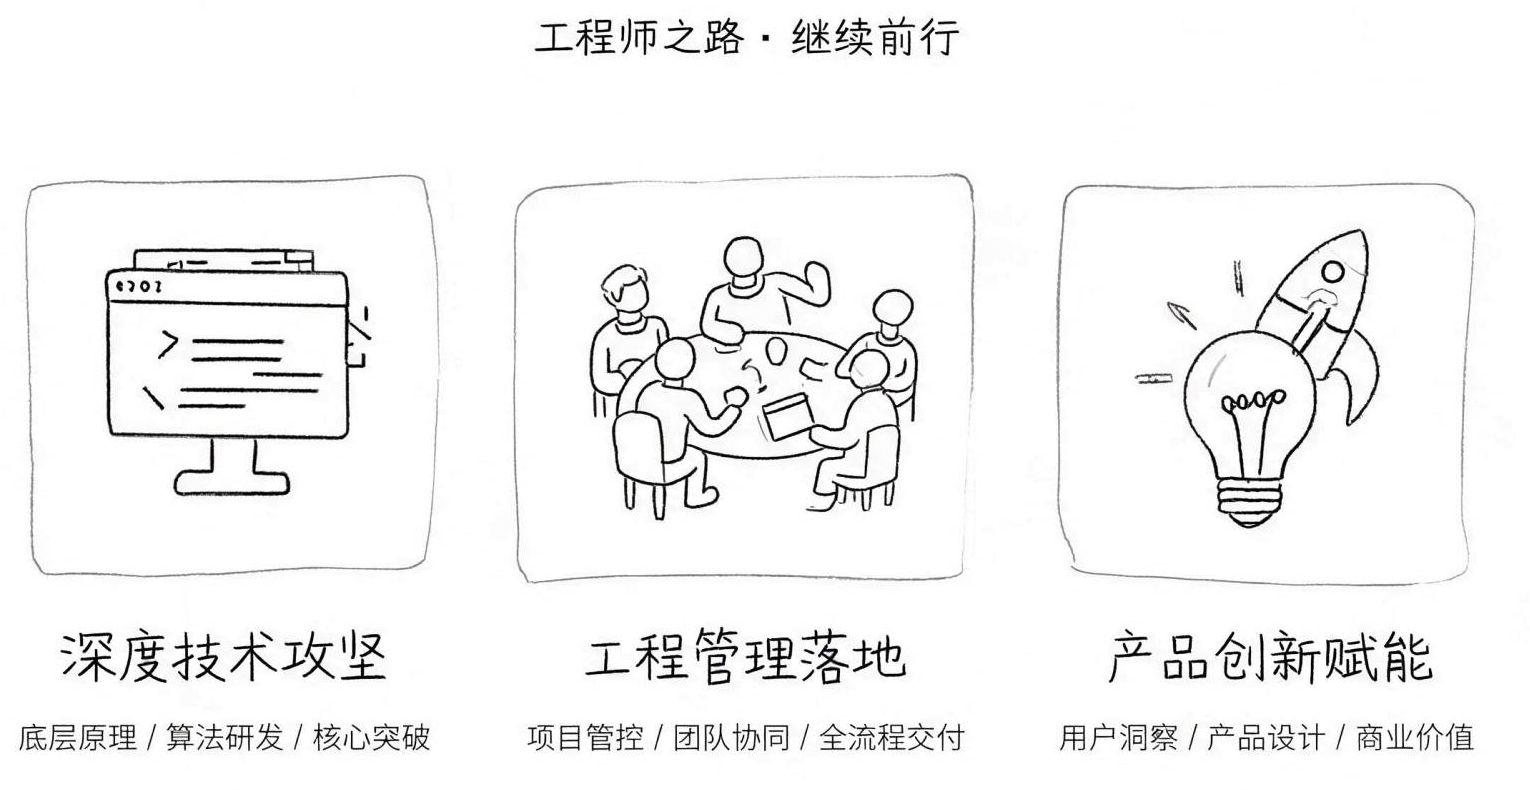

*原课件第 6 页：“工程师之路·继续前行”。*

| 方向 | 课件列出的关注点 | 方向含义 |
|---|---|---|
| 深度技术攻坚 | 底层原理、算法研发、核心突破 | 继续追究模型、算法和控制背后的原理，解决关键技术问题 |
| 工程管理落地 | 项目管控、团队协同、全流程交付 | 把技术工作组织成能够协作、推进与交付的项目 |
| 产品创新赋能 | 用户洞察、产品设计、商业价值 | 从用户任务出发，思考机器人应提供怎样的功能与使用价值 |

课件把这三项作为继续发展的方向，没有给出各方向的必修课程、能力等级或固定先后关系。后面几页转向技术思考，展示完成入门仿真之后还可以继续研究哪些问题。


## 6. 现实与仿真：物理参数需要对齐

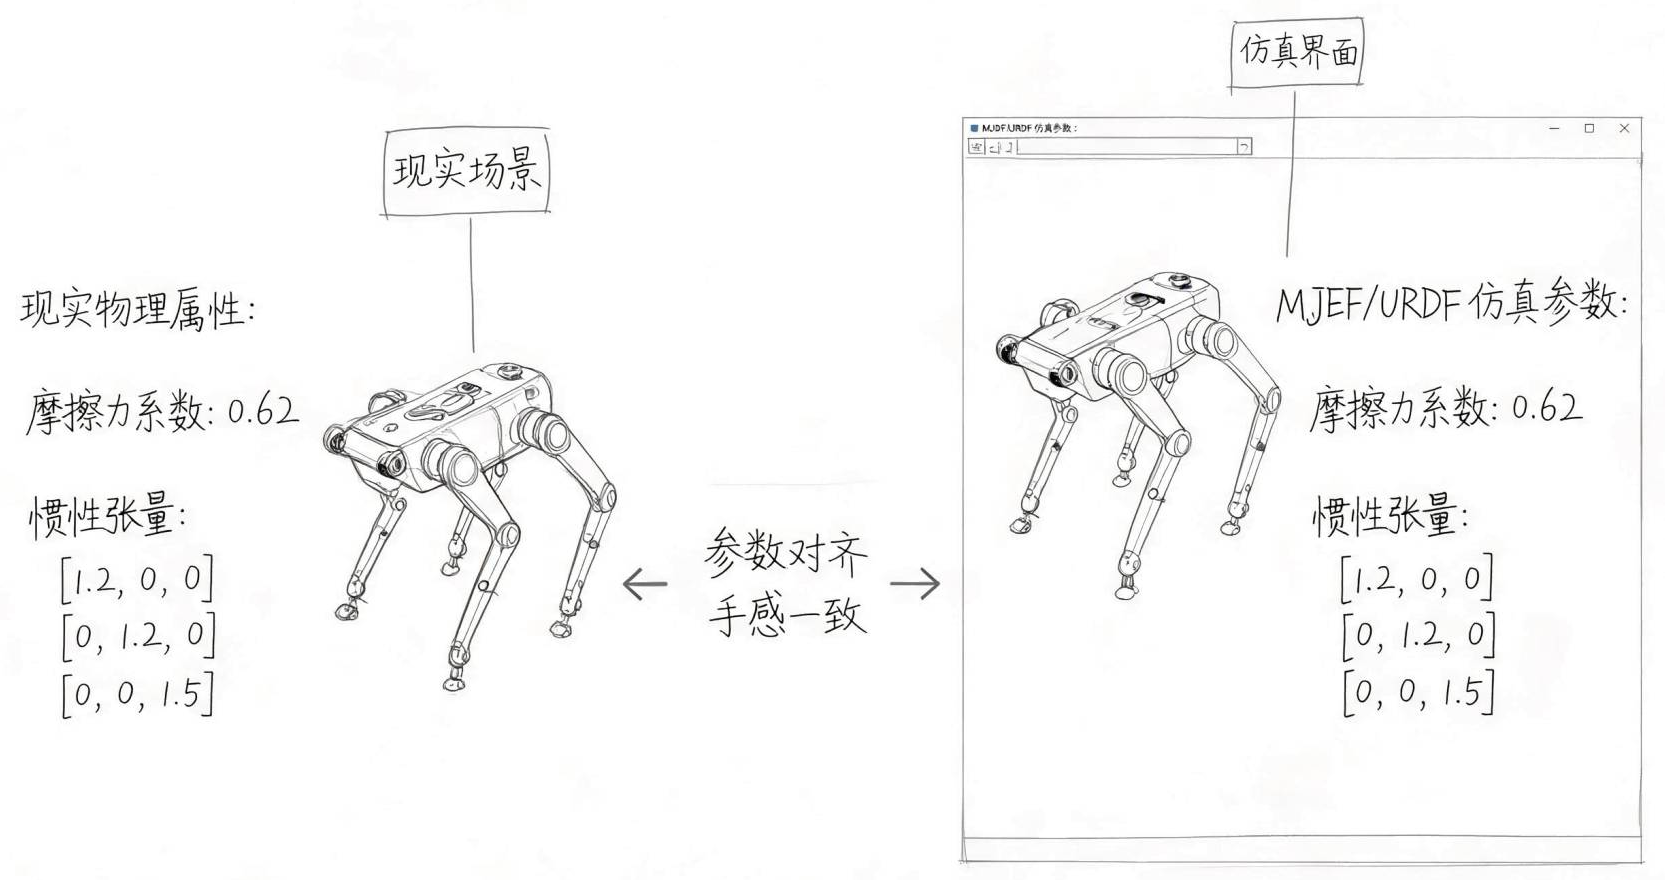

*原课件第 7 页：用四足机器人示意现实物理属性与仿真参数之间的对应关系。*

画面两侧分别标出“现实场景”和“仿真界面”，中间写着“参数对齐、手感一致”。课件希望说明：仿真模型除了外观，还需要用物理参数描述真实对象的行为。

图中的示例数值如下，两侧使用同样的数值作对照：

| 属性 | 图中示例 |
|---|---|
| 摩擦力系数 | `0.62` |
| 惯性张量 | 三行分别为 `[1.2, 0, 0]`、`[0, 1.2, 0]`、`[0, 0, 1.5]` |

摩擦影响接触时的相互作用，惯性描述刚体对转动变化的响应。参数对齐关注的是模型对物理行为的描述，课件没有给出测量、辨识或校准过程。

**原图标注说明：**右侧写作“MJEF/URDF 仿真参数”。MuJoCo 本系列使用的模型格式为 MJCF/XML；原图中的“MJEF”不作为实际配置格式名使用。

**工程补充：**上表数值是示意，课件没有标明惯性的单位、参考坐标系或所对应的具体刚体，不能直接抄进 T800 模型。实际配置还需核对文件格式、字段含义及接触模型。即使某几个参数写成相同数值，也需要通过运动与接触实验判断仿真和现实的差异。


## 7. 步态优化：平滑、类生物轨迹与稳定性

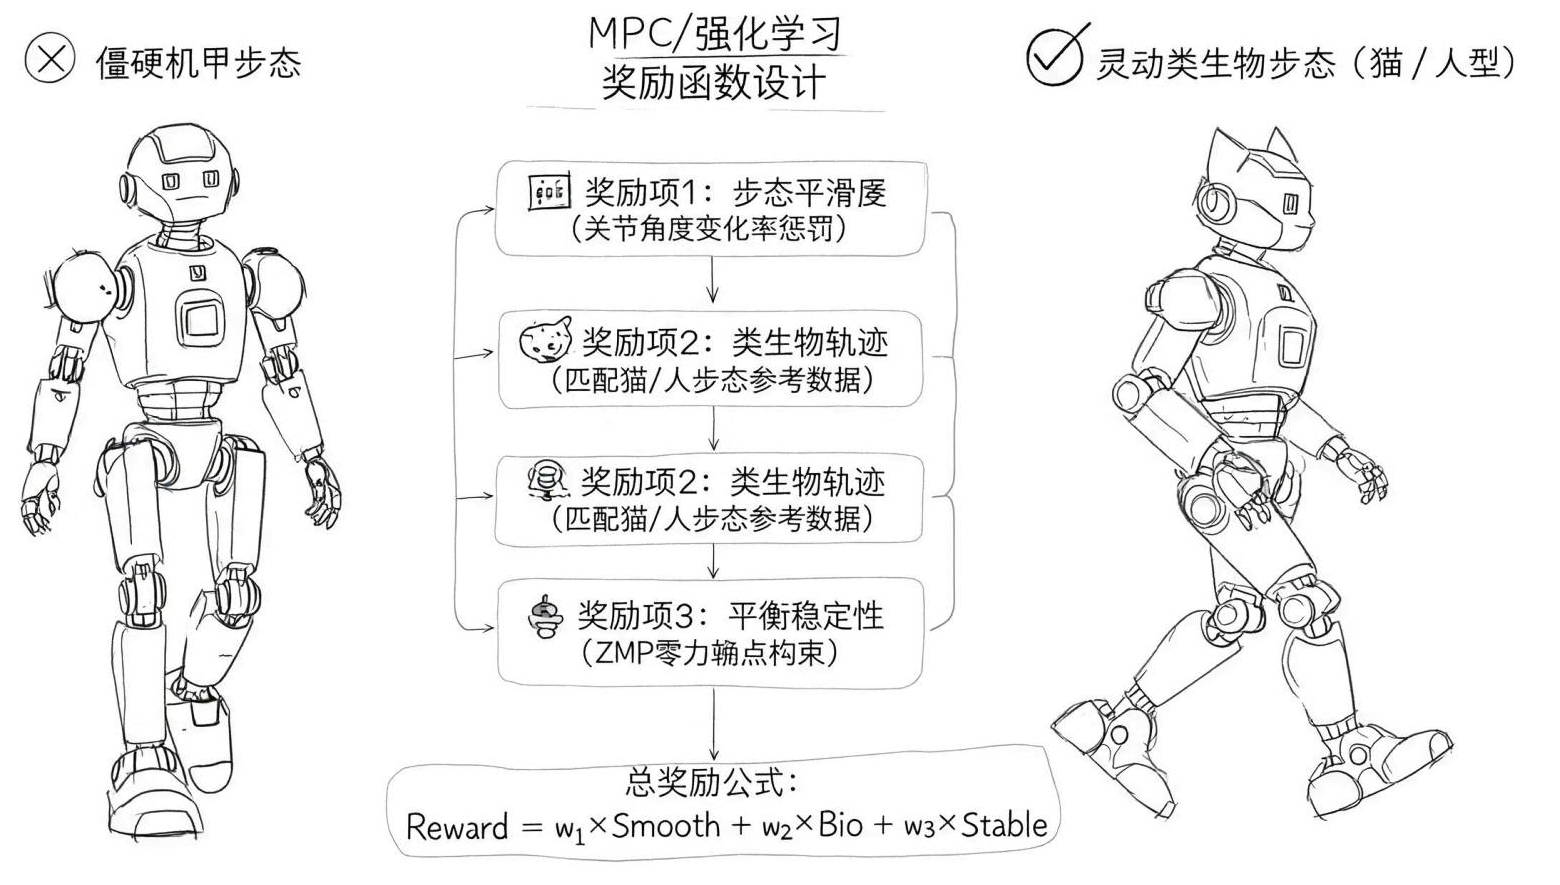

*原课件第 8 页：对比“僵硬机甲步态”与“灵动类生物步态（猫／人型）”，并列出奖励设计思路。*

课件在“MPC／强化学习、奖励函数设计”的标题下，列出三个不同的评价方向：

| 评价方向 | 原图中的说明 | 希望关注的运动特征 |
|---|---|---|
| 步态平滑度 `Smooth` | 关节角度变化率惩罚 | 关节运动的变化是否过于剧烈 |
| 类生物轨迹 `Bio` | 匹配猫／人步态参考数据 | 运动轨迹与所选参考步态是否接近 |
| 平衡稳定性 `Stable` | ZMP 零力矩点约束 | 行走中的支撑与平衡情况 |

图中给出的总奖励表达式为：

$$
Reward=w_1\times Smooth+w_2\times Bio+w_3\times Stable
$$

`w1`、`w2`、`w3` 表示不同评价项的权重，用于表达这些目标在总评价中的相对影响。课件没有给出权重数值、各项的计算公式、参考数据或训练流程，所以这仍是设计思路，不能直接作为完整训练配置。

**原图标注说明：**“奖励项 2：类生物轨迹”在图中重复出现两次，文字相同。上表按不同内容整理为三类，与底部的三项公式对应，原图保留。

**工程补充：**惩罚项与奖励项需要约定符号和尺度。例如，若把变化率大小作为正惩罚值，就要在最大化奖励时扣除，或将该项定义为负值。ZMP 是零力矩点概念，课件没有展开其计算与适用条件，不能凭这一项保证运动在所有情况下稳定。

MPC（模型预测控制）通常依据模型在有限时域内优化控制量，强化学习则通过交互反馈学习策略。两者都可以考虑平滑、参考运动和稳定性，但图中的并列名称不表示使用同一套训练或控制实现。本课也没有运行步态优化实验。


## 8. 物体交互：把感知与动作联系起来

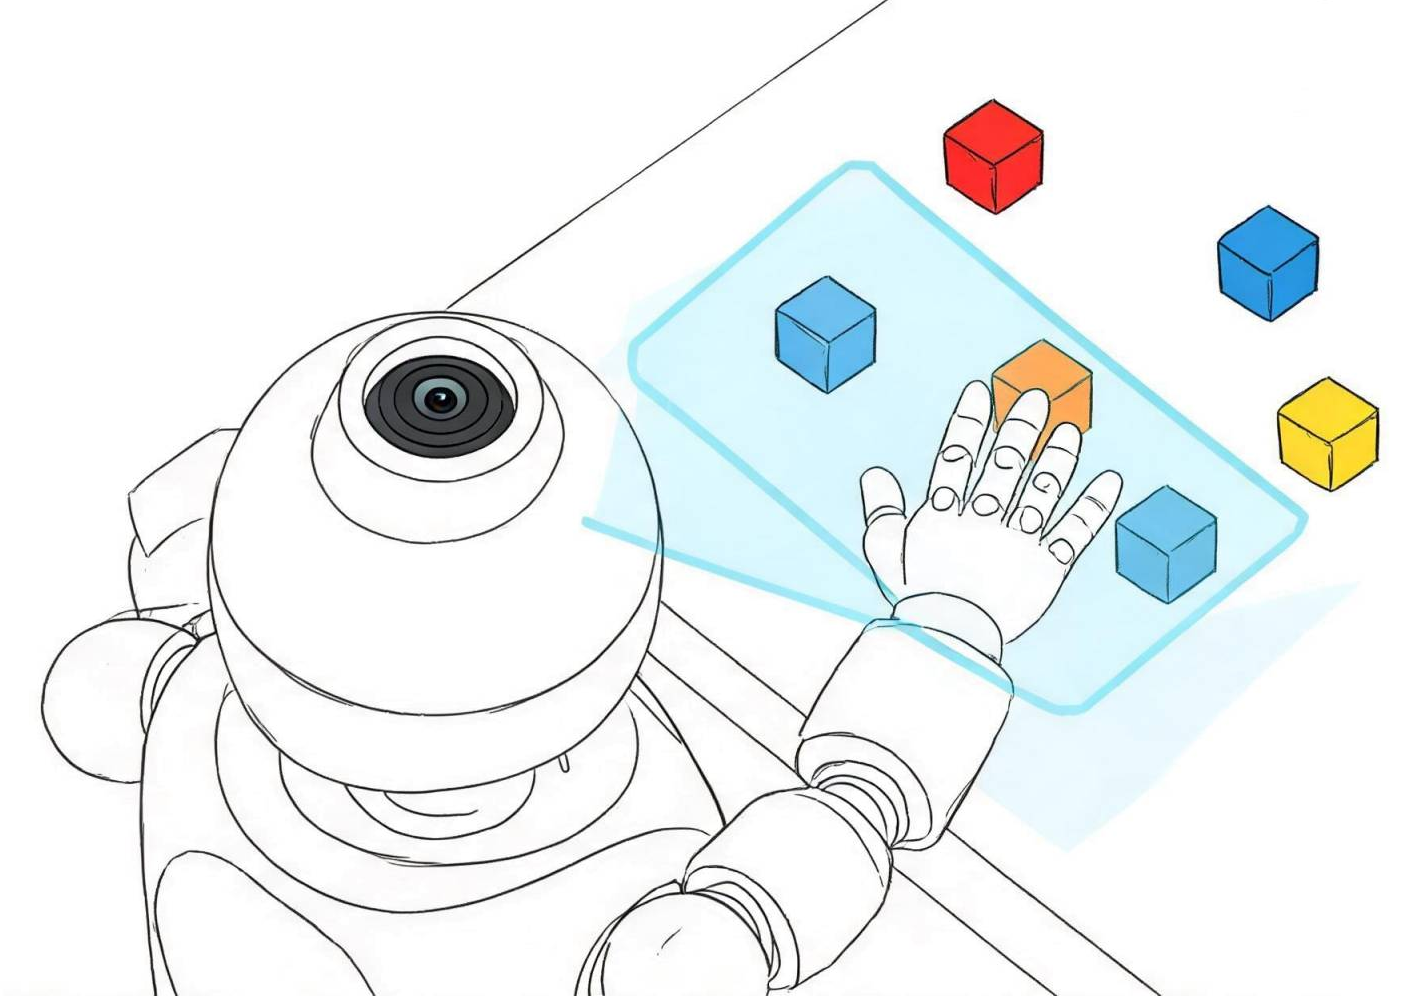

*原课件第 9 页：机器人相机、视野区域、手部和多个彩色方块，没有额外文字或算法说明。*

这张图把任务对象、感知范围与机器人动作放在同一个场景中。联系前面的课程，交互任务需要同时考虑物体的位置、身体部件的位置，以及两者的空间关系，才能讨论下一步动作。

图中可以看见相机和伸向方块的手，但没有展示检测框、深度值、抓取点、力传感器数据或控制流程。因此，它只支持理解视觉与物体交互的关联，不能据此确定具体检测算法，也不能认定抓取已成功。

**工程补充：**视觉反馈帮助描述机器人与目标之间的关系，接触力反馈帮助描述相互作用的受力情况。任务可以结合多种反馈，实际采用哪些信息，要查看传感器、观测定义和控制程序。这也为下一页的问题提供了背景。


## 9. 分析机器人系统时的五个问题

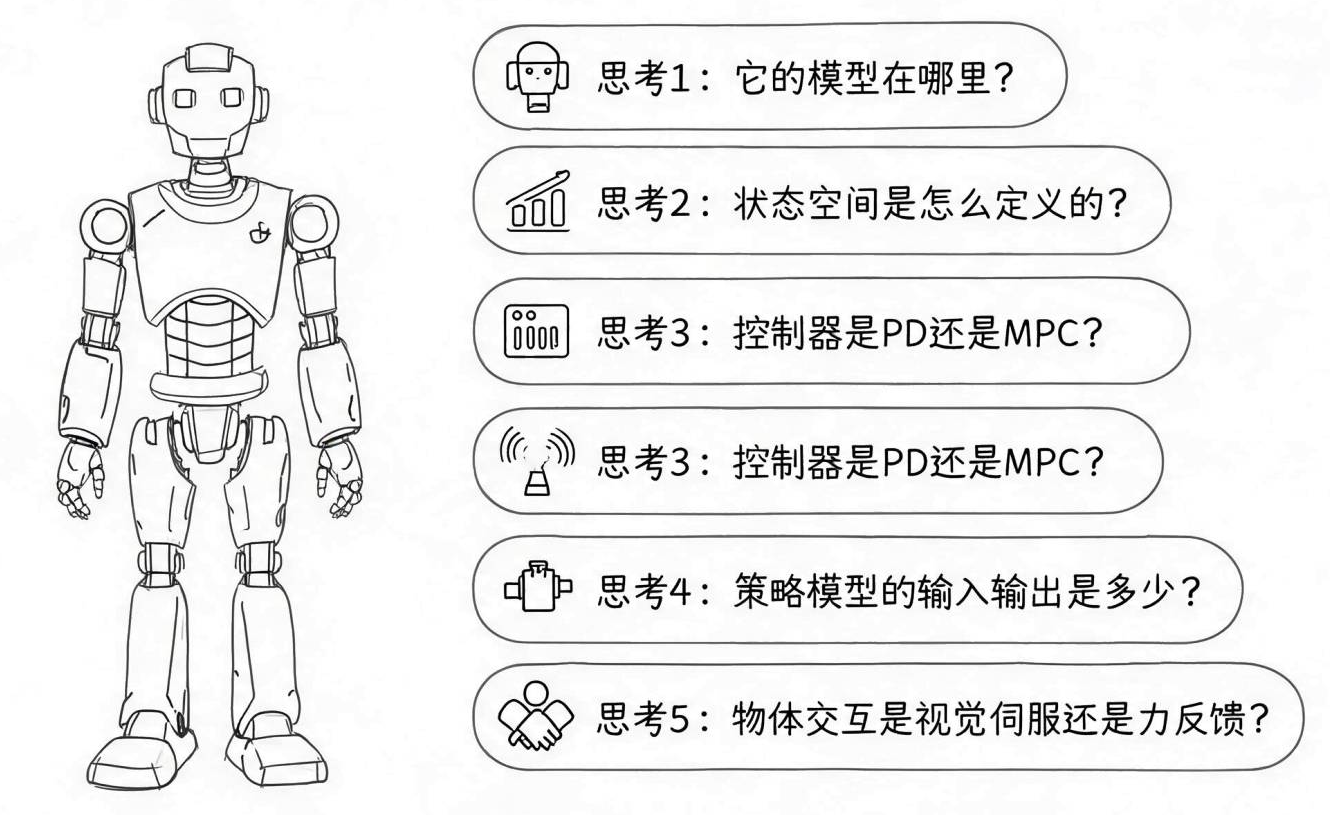

*原课件第 10 页：面对一个机器人系统，继续追问模型、状态、控制、策略接口与交互方式。*

| 课件中的问题 | 阅读或分析系统时要查清的内容 |
|---|---|
| 它的模型在哪里？ | 场景入口、机器人结构、关节与执行器配置，以及模型依赖的资源 |
| 状态空间是怎么定义的？ | 系统用哪些变量描述状态，策略实际能获得哪些观测，采用什么坐标系与数据约定 |
| 控制器是 PD 还是 MPC？ | 目标怎样转换为控制作用，各层控制器分别承担什么职责 |
| 策略模型的输入输出是多少？ | 输入输出的维度、分量含义、排列与缩放，以及动作怎样进入控制环节 |
| 物体交互是视觉伺服还是力反馈？ | 控制依据什么反馈调整动作，视觉与接触信息怎样参与任务 |

**原图标注说明：**“思考 3：控制器是 PD 还是 MPC？”在原图中重复出现一次，因此画面有六个问题框，上表保留五个不同问题，不另造第六项。

**工程补充：**状态空间与策略观测并不总相同，策略可能只获得完整系统状态的一部分。PD 与 MPC 也可能处于不同控制层级，不能仅凭名称把整个系统归为互斥的两类。视觉伺服指利用视觉反馈不断调整运动，它与力反馈可以共同使用。

对本系列已讨论的方案，可以先回顾 1083 维观测，以及第 12 节中 22 维上一帧 Action 的约定，再继续核对实际模型接口。维度之外，还需明确每个数代表什么。课件本页没有提供新的策略文件或 MNN 张量信息，不能把概念维度当作已验证的模型输入输出形状。


## 10. 创造者视角与课程结束

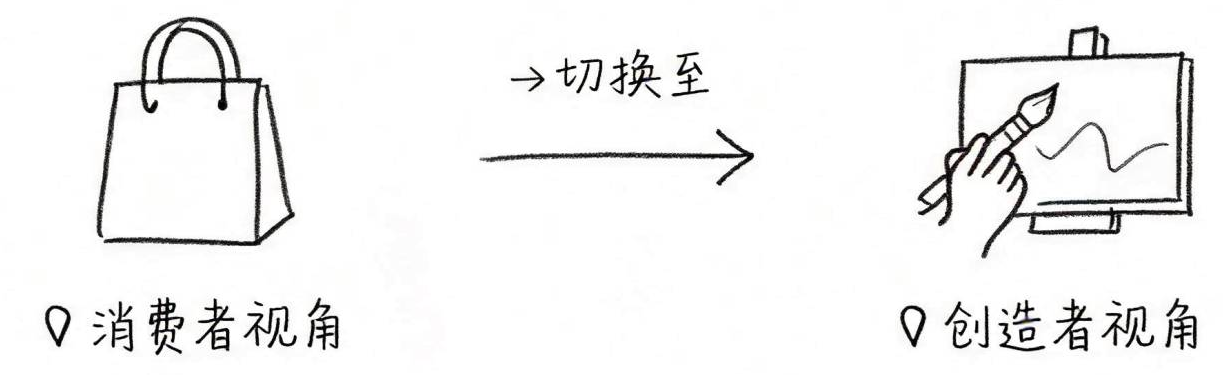

*原课件第 11 页：“消费者视角”切换至“创造者视角”。*

课件在提出技术问题后，用这张图提醒学习者继续分析系统怎样构成。看到机器人完成动作，可以进一步查明模型、输入、控制与反馈怎样共同产生这个结果，并通过修改和验证积累自己的工程经验。

后续结课页面鼓励继续实践，在遇到代码问题时调试，在学习新技术时讨论论文，并继续探索物理世界中的机器人任务。这些页面没有提供新的技术实现，本篇不扩展成额外课程或操作清单。

本节回顾了仿真开发的主要环节，保留了三个发展方向、物理参数对齐、步态评价和系统分析问题。完成本节，应能沿这些问题回看自己的程序，区分概念示意、模型配置和实际验证结果。本篇没有执行参数校准、策略训练、物体抓取或实机测试。
